<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

**Worker: [vgi-kalshi](https://github.com/Query-farm/vgi-kalshi)**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-kalshi/blob/main/notebooks/03_reconcile_trades_and_candles.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-kalshi/blob/main/notebooks/README.md)

# Closing price and execution average answer different questions

Can a complete trade tape explain the hourly candles, including an hour with no executions? Then regroup the same trades without losing the price × quantity numerator.

**Synthetic data, real SQL worker.** Every `DEMOWX` contract, event, price, quantity, timestamp and source URL in this example is fictional. A strict loopback HTTP server supplies the declared responses to the published worker; there is no live fallback and no authentication. The helper creates an empty temporary SQL secret directory with persistent secrets disabled. Prices are USD per one-dollar YES contract, quantities are contracts, and all times are UTC.

In [1]:
REPORT_MINUTES = 60  # 60 or 120; experiment: 120

Install the shared **base** package for Colab. The local locked environment adds its `[runner]` extra. The next cell validates the current kernel before importing the companion.

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.6":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.6"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

In [3]:
from vgi_notebooks import check_runtime, prepare

check_runtime()
prepare("kalshi-surfaces")
import kalshi_surfaces as example  # noqa: E402

example.initialize(globals(), "tape")

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
SET TimeZone='UTC';
ATTACH 'kalshi' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-kalshi@v1.3.0 vgi-kalshi',
    auth 'off');

,Success


Fetch one fictional contract over a fixed four-hour window. The API arguments are explicit epoch seconds. The candle endpoint returns hourly bars; our reporting interval is a separate analytical choice. All six trades fall strictly inside the window, so no trade on a boundary is silently assigned by convention.

In [5]:
%%sql
CREATE TABLE tape AS
SELECT * FROM kalshi.main.trades('DEMOWX-26NOV15-T20',
    min_ts => 1794643200, max_ts => 1794657600);
CREATE TABLE hourly_candles AS
SELECT * FROM kalshi.main.candlesticks('DEMOWX', 'DEMOWX-26NOV15-T20',
    period_interval => 60, start_ts => 1794643200, end_ts => 1794657600);

,Count


In [6]:
%%sql trades <<
SELECT trade_id, created_time, taker_side, yes_price_dollars, count_fp FROM tape ORDER BY created_time;

In [7]:
display(trades)

,trade_id,created_time,taker_side,yes_price_dollars,count_fp
0,DEMOWX-26NOV15-T20-1,2026-11-14 08:10:00+00:00,yes,0.4,10.0
1,DEMOWX-26NOV15-T20-2,2026-11-14 08:50:00+00:00,no,0.6,30.0
2,DEMOWX-26NOV15-T20-3,2026-11-14 10:10:00+00:00,yes,0.5,20.0
3,DEMOWX-26NOV15-T20-4,2026-11-14 10:50:00+00:00,no,0.8,40.0
4,DEMOWX-26NOV15-T20-5,2026-11-14 11:10:00+00:00,yes,0.7,5.0
5,DEMOWX-26NOV15-T20-6,2026-11-14 11:50:00+00:00,no,0.9,15.0


Match each candle to trades in its preceding hour. SQL uses half-open intervals `[start, end)`; no synthetic execution falls exactly at an hour boundary. Keep the candle row for the quiet hour: zero contracts and NULL price are different facts. The candle close is the last trade, while VWAP weights every execution by quantity.

In [8]:
%%sql
CREATE TABLE hourly_reconciliation AS
SELECT c.end_period_ts, c.volume_fp, c.price_close_dollars,
       count(t.trade_id) AS executions, coalesce(sum(t.count_fp), 0) AS tape_contracts,
       sum(t.yes_price_dollars*t.count_fp)/nullif(sum(t.count_fp),0) AS vwap_dollars,
       arg_max(t.yes_price_dollars, t.created_time) AS tape_close_dollars
FROM hourly_candles c LEFT JOIN tape t
  ON t.created_time >= c.end_period_ts - INTERVAL '1 hour' AND t.created_time < c.end_period_ts
GROUP BY c.end_period_ts, c.volume_fp, c.price_close_dollars;

,Count


In [9]:
%%sql hourly <<
SELECT * FROM hourly_reconciliation ORDER BY end_period_ts;

In [10]:
display(hourly)

,end_period_ts,volume_fp,price_close_dollars,executions,tape_contracts,vwap_dollars,tape_close_dollars
0,2026-11-14 09:00:00+00:00,40.0,0.6,2,40.0,0.55,0.6
1,2026-11-14 10:00:00+00:00,0.0,NaN,0,0.0,NaN,NaN
2,2026-11-14 11:00:00+00:00,60.0,0.8,2,60.0,0.70,0.8
3,2026-11-14 12:00:00+00:00,20.0,0.9,2,20.0,0.85,0.9


Reporting windows begin at 08:00 UTC. Carry both the price × quantity sum (USD) and the quantity (contracts) into every bucket. Their ratio is USD per contract. Include empty buckets explicitly; do not replace their undefined ratio with zero.

In [11]:
%%sql
CREATE TABLE reporting AS
WITH windows AS (
    SELECT TIMESTAMPTZ '2026-11-14 08:00:00+00' + i * INTERVAL '1 minute' AS bucket_start
    FROM range(0, 240, {{REPORT_MINUTES}}) r(i)
)
SELECT w.bucket_start, count(t.trade_id) AS executions,
       coalesce(sum(t.count_fp), 0) AS contracts,
       coalesce(sum(t.yes_price_dollars*t.count_fp), 0) AS yes_notional_dollars,
       sum(t.yes_price_dollars*t.count_fp)/nullif(sum(t.count_fp),0) AS vwap_dollars,
       arg_max(t.yes_price_dollars, t.created_time) AS last_price_dollars
FROM windows w LEFT JOIN tape t
  ON t.created_time >= w.bucket_start
 AND t.created_time < w.bucket_start + {{REPORT_MINUTES}} * INTERVAL '1 minute'
GROUP BY w.bucket_start;

,Count


In [12]:
%%sql report <<
SELECT * FROM reporting ORDER BY bucket_start;

,bucket_start,executions,contracts,yes_notional_dollars,vwap_dollars,last_price_dollars
0,2026-11-14 08:00:00+00:00,2,40.0,22.0,0.55,0.6
1,2026-11-14 09:00:00+00:00,0,0.0,0.0,NaN,NaN
2,2026-11-14 10:00:00+00:00,2,60.0,42.0,0.70,0.8
3,2026-11-14 11:00:00+00:00,2,20.0,17.0,0.85,0.9


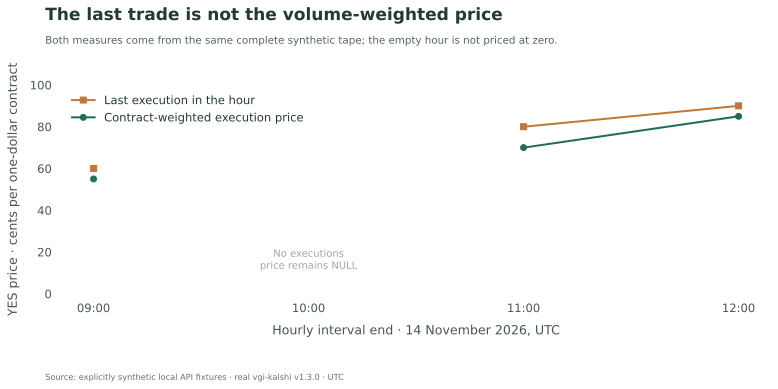

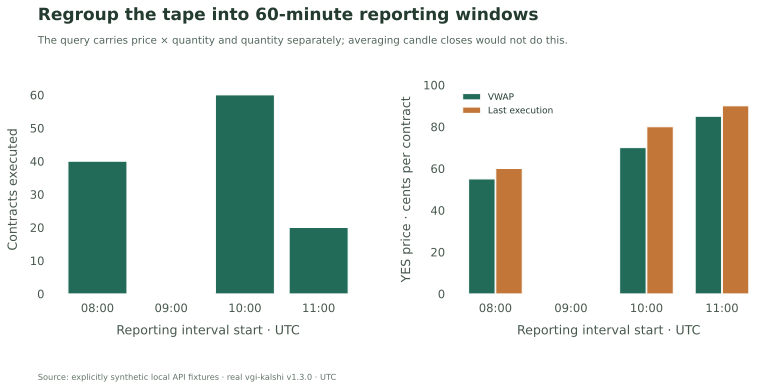

In [13]:
display(report)
example.tape_charts(hourly, report, REPORT_MINUTES)

In [14]:
example.describe_tape(report, REPORT_MINUTES)

The **60-minute** report contains **4 windows** and **120 executed contracts**. Summed price × quantity is **81.00 USD**, so the whole-window YES VWAP is **67.50 cents**. Regrouping changes the within-window averages and last trades, while the quantity and numerator stay fixed. This describes executions; it does not measure resting depth or establish an executable price.

In [15]:
%%sql checks <<
SELECT 'six unique executions' AS invariant, (SELECT count(*)=6 AND count(DISTINCT trade_id)=6 FROM tape) AS passed
UNION ALL SELECT 'four hourly candles', (SELECT count(*) FROM hourly_candles)=4
UNION ALL SELECT 'every hourly volume reconciles', (SELECT bool_and(volume_fp=tape_contracts) FROM hourly_reconciliation)
UNION ALL SELECT 'every hourly close reconciles', (SELECT bool_and(price_close_dollars IS NOT DISTINCT FROM tape_close_dollars) FROM hourly_reconciliation)
UNION ALL SELECT 'quiet hour retains NULL price', (SELECT count(*) FROM hourly_reconciliation WHERE executions=0 AND price_close_dollars IS NULL AND vwap_dollars IS NULL)=1
UNION ALL SELECT 'all 120 contracts retained', (SELECT sum(contracts) FROM reporting)=120
UNION ALL SELECT '81 USD numerator retained', (SELECT sum(yes_notional_dollars) FROM reporting)=81
UNION ALL SELECT 'complementary YES and NO prices', (SELECT bool_and(yes_price_dollars+no_price_dollars=1) FROM tape)
UNION ALL SELECT 'report buckets preserve six executions', (SELECT sum(executions) FROM reporting)=6;

In [16]:
example.check(checks)
example.audit(["/markets/trades", "/markets/candlesticks"])

,invariant,passed
0,six unique executions,True
1,four hourly candles,True
2,every hourly volume reconciles,True
3,every hourly close reconciles,True
4,quiet hour retains NULL price,True
5,all 120 contracts retained,True
6,81 USD numerator retained,True
7,complementary YES and NO prices,True
8,report buckets preserve six executions,True


**Verified:** 2 local GET requests, no unexpected requests, and an empty SQL secret inventory. Every displayed source row came through the released worker.

**Experiment:** change only `REPORT_MINUTES` from 60 to 120. The first chart and the raw six-trade/four-candle reconciliation must remain unchanged. The second chart combines adjacent hours. Both runs retain 120 contracts and an 81 USD numerator; averaging the displayed closes would not preserve this weighting.

In [17]:
example.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-kalshi](https://github.com/Query-farm/vgi-kalshi)
